# NLP Text Classification: Social Media Sentiment

**Codveda Data Science Internship, Level 3, Task 2: Natural Language Processing (Text Classification)**

This notebook classifies short social media posts into **Positive**, **Negative**, and **Neutral** using TF-IDF features and two classical classifiers: Logistic Regression and Complement Naive Bayes.

The analysis includes label grouping, data cleaning, exploratory analysis, stratified train/test splitting, text preprocessing, TF-IDF vectorization, model evaluation, error analysis, cross-validation, conclusions, and limitations.

> **Dataset note:** Set `DATA_PATH` below to the location of the CSV dataset before running the notebook.


### Optional dependency installation
If any package is missing, run the following in a notebook cell:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn nltk emoji
```


In [5]:
import sys

print(sys.executable)

c:\Users\hp\anaconda3\python.exe


In [6]:
import re
import emoji
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay





In [7]:
# Update this path to your dataset CSV before running the notebook.
DATA_PATH = "Sentiment_dataset.csv"

df = pd.read_csv(DATA_PATH)
df.head()


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


Install anything missing with `pip install pandas numpy matplotlib seaborn scikit-learn nltk emoji`.

---

## 3. Load and inspect the data


In [8]:
df.head()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


**Findings**

- The dataset has **732 posts and 15 columns**, with **no missing values**.
- Columns: `Unnamed: 0.1`, `Unnamed: 0`, `Text`, `Sentiment`, `Timestamp`, `User`, `Platform`, `Hashtags`, `Retweets`, `Likes`, `Country`, `Year`, `Month`, `Day`, `Hour`.
- `Unnamed: 0.1` and `Unnamed: 0` are leftover index columns from saving the CSV more than once, so they were dropped.
- Only `Text` (input) and `Sentiment` (label) are used for this task. Engagement and date columns are not part of text classification.
- Some posts contain emojis and hashtags, which need a deliberate handling decision (see section 11).


In [9]:
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])
df["Text"] = df["Text"].str.strip()
df["Sentiment"] = df["Sentiment"].str.strip()


---

## 4. Label audit


In [10]:
pd.set_option("display.max_rows", 191)
df["Sentiment"].value_counts()

df["Text"].duplicated().sum()
df["Text"].str.split().str.len().describe()


count    732.000000
mean      13.206284
std        4.853229
min        4.000000
25%        9.000000
50%       13.000000
75%       17.000000
max       25.000000
Name: Text, dtype: float64

**Findings**

- The `Sentiment` column has **191 distinct labels**, not three. They are mostly *emotions* (Joy, Despair, Gratitude, Curiosity) rather than polarity labels, with a long tail of poetic labels such as "Celestial Wonder" and "Whispers of the Past".
- The largest labels are Positive (45), Joy (44), Excitement (37), Contentment (19), Neutral (18), Gratitude (18) and Curiosity (16). **Many labels have only one or two posts.**
- A 191-class classifier is not trainable on 732 posts, because a class with one example cannot be learned or tested, and a stratified split would fail.
- There were **26 duplicated texts**.
- Posts are short: mean **13.2 words**, minimum 4, maximum 25.

**Why this matters.** The raw data is an *emotion detection* dataset. The task asks for *polarity* classification (Positive / Negative / Neutral), so the labels were grouped into three classes. The grouping is the most consequential decision in the project and is documented in full below.

---

## 5. Grouping 191 emotion labels into 3 classes

**Method.** Obvious labels were assigned directly (Joy, Excitement, Gratitude to Positive; Despair, Grief, Anger to Negative; Indifference, Ambivalence to Neutral). For ambiguous labels, the dictionary meaning of the label was ignored and the **actual posts were read**:


In [11]:
curiosity_df = df.loc[df["Sentiment"] == "Curiosity", ["Text", "Sentiment"]]

batch1_labels = ["Confusion", "Acceptance", "Surprise", "Numbness"]
batch1_df = (df.loc[df["Sentiment"].isin(batch1_labels), ["Text", "Sentiment"]]
               .sort_values(by="Sentiment"))


### Decisions for ambiguous labels

| Label | Posts | What the posts say | Class |
|---|---|---|---|
| Curiosity | 16 | Discovery, learning, adventure; none worried | Positive |
| Nostalgia | 11 | Warm and fond; about half are bittersweet, none clearly unhappy | Positive |
| Acceptance | 8 | Peaceful, self-love, "beauty in imperfections" | Positive |
| Confusion | 8 | Lost, perplexed, unsettled | Negative |
| Numbness | 6 | Emotional shielding, turmoil, storms | Negative |
| Surprise | 6 | Four clearly happy posts; two sarcastic rows dropped (section 6) | Positive |
| Arousal | 4 | All about excitement for upcoming events | Positive |
| Boredom | 4 | Flat and listless ("stagnant pool of indifference"); can be felt positively or negatively | Neutral |
| Overwhelmed | 4 | Heavy and distressed; one grateful row dropped (section 6) | Negative |
| Emotion | 2 | Moved at Adele concerts; enjoying music | Positive |
| Renewed Effort | 1 | Frustration first, resolve second | Negative |
| Solitude | 1 | Dark, heavy tone | Negative |
| Sympathy | 1 | Compassion about someone's misfortune | Negative |
| Bittersweet | 1 | Farewell to a friend; genuinely mixed | Dropped |
| Whispers of the Past | 1 | Wonder at exploring an ancient city, like the Exploration posts | Positive |

Labels with an obvious reading from their posts: Anticipation, Exploration, Hypnotic, Intrigue, Journey, Mischievous and Suspense went to Positive; Yearning and Challenge went to Negative.

### Class definitions

- **Positive:** joy, excitement, gratitude, pride, wonder, love, curiosity, hope and similar.
- **Negative:** sadness, anger, fear, shame, envy, frustration, loneliness and similar.
- **Neutral:** flat or mixed states (Neutral, Indifference, Ambivalence, Boredom, Reflection, Contemplation, Pensive).

### A note on sentiment analysis types

The raw labels are *emotion detection* labels. Grouping them into Positive / Negative / Neutral converts the dataset into a *polarity-based* problem, which is what the task asks for. Fine-grained (scale-based) sentiment does not fit this data because the labels are categories, not ratings. Aspect-based sentiment analysis does not help here either: the mixed Nostalgia posts have one subject and one blended feeling, not separate opinions about separate aspects. A fourth "Mixed" class was considered (Nostalgia plus Bittersweet) but rejected because about 12 posts is too few to train or evaluate on.

---

## 6. Removing contradictory rows

Five rows were removed. **Rule:** a row was dropped when its text clearly contradicted the sentiment implied by its label, or (for row 340) when it was genuinely mixed and the label was a single-row outlier.

| Row | Label | Why dropped |
|---|---|---|
| 584 | Surprise | Sarcastic joke about procrastination; not surprise |
| 588 | Surprise | Joke about staring at the clock in class; boredom, not surprise |
| 581 | Boredom | "Ran out of snacks... Crisis level: Emergency!" is a playful complaint, not boredom |
| 337 | Overwhelmed | "Overwhelmed by the support received" is grateful, not distressed |
| 340 | Bittersweet | Farewell to a dear friend; truly mixed |


In [12]:
df = df.drop(index=[584, 588, 581, 337, 340], errors="ignore")
df.shape   # (727, 13)


(727, 13)

Run the drop once on `df` (not on a filtered view). `errors="ignore"` makes it safe to re-run.

---

## 7. Applying the label mapping





In [13]:
positive = [
    "Positive", "Joy", "Excitement", "Contentment", "Gratitude", "Curiosity", "Serenity",
    "Happy", "Nostalgia", "Hopeful", "Awe", "Acceptance", "Euphoria", "Enthusiasm", "Pride",
    "Elation", "Determination", "Surprise", "Playful", "Inspiration", "Hope", "Inspired",
    "Empowerment", "Happiness", "Compassion", "Proud", "Reverence", "Thrill", "Enchantment",
    "Compassionate", "Tenderness", "Arousal", "Fulfillment", "Grateful", "Admiration",
    "Calmness", "Anticipation", "Love", "Amusement", "Accomplishment", "Satisfaction",
    "Adventure", "Wonder", "Harmony", "Empathetic", "Creativity", "Kind", "Confident",
    "Free-spirited", "Zest", "Affection", "Enjoyment", "Adoration", "Rejuvenation",
    "Resilience", "Coziness", "Exploration", "Mischievous", "Emotion", "Tranquility",
    "Whimsy", "Radiance", "Captivation", "FestiveJoy", "Intrigue", "Melodic", "Optimism",
    "Motivation", "JoyfulReunion", "Overjoyed", "Wonderment", "Appreciation", "Confidence",
    "Blessed", "Mindfulness", "Elegance", "Marvel", "Spark", "Adrenaline", "ArtisticBurst",
    "CulinaryOdyssey", "Immersion", "Freedom", "Dazzle", "InnerJourney", "DreamChaser",
    "PlayfulJoy", "Amazement", "Success", "Friendship", "Romance", "Grandeur", "Energy",
    "Celebration", "Charm", "Ecstasy", "Colorful", "Positivity", "Kindness", "Touched",
    "Engagement", "Journey", "Iconic", "Connection", "Hypnotic", "Suspense", "Triumph",
    "Solace", "Heartwarming", "Mesmerizing", "Vibrancy", "Imagination", "Envisioning History",
    "Joy in Baking", "Breakthrough", "Culinary Adventure", "Winter Magic", "Ocean's Freedom",
    "Runway Creativity", "Creative Inspiration", "Celestial Wonder", "Nature's Beauty",
    "Thrilling Journey", "Relief", "Whispers of the Past",
]

negative = [
    "Despair", "Loneliness", "Grief", "Sad", "Embarrassed", "Confusion", "Melancholy",
    "Frustration", "Regret", "Numbness", "Bad", "Hate", "Betrayal", "Frustrated",
    "Bitterness", "Disgust", "Overwhelmed", "Negative", "Desolation", "Shame", "Dismissive",
    "Heartbreak", "Devastated", "Jealous", "Jealousy", "Resentment", "Bitter", "Envious",
    "Fearful", "Helplessness", "Intimidation", "Anxiety", "Anger", "Fear", "Sadness", "Envy",
    "Disappointed", "Disappointment", "Sorrow", "Loss", "Apprehensive", "Yearning",
    "Isolation", "Suffering", "EmotionalStorm", "Heartache", "Desperation", "Darkness",
    "Solitude", "Exhaustion", "Ruins", "LostLove", "Challenge", "Obstacle", "Sympathy",
    "Pressure", "Renewed Effort", "Miscalculation",
]

neutral = [
    "Neutral", "Indifference", "Ambivalence", "Boredom", "Reflection", "Contemplation",
    "Pensive",
]

groups = {"Positive": positive, "Negative": negative, "Neutral": neutral}
label_to_group = {label: group for group, labels in groups.items() for label in labels}

print(len(label_to_group))                 # 190
df["Sentiment_Group"] = df["Sentiment"].map(label_to_group)

print(df["Sentiment_Group"].isna().sum())  # 0
print(df["Sentiment_Group"].value_counts())
print(df["Sentiment_Group"].value_counts(normalize=True))
print(df.shape)


190
0
Sentiment_Group
Positive    493
Negative    194
Neutral      40
Name: count, dtype: int64
Sentiment_Group
Positive    0.678129
Negative    0.266850
Neutral     0.055021
Name: proportion, dtype: float64
(727, 14)




**Findings**

- **190 labels** were mapped (191 minus Bittersweet, which was dropped). `Series.map` returns NaN for any label missing from the dictionary, so the NaN count is a check that every label is covered. It is **0**.
- Resulting class balance over 727 posts:

| Class | Posts | Share |
|---|---|---|
| Positive | 493 | 67.8% |
| Negative | 194 | 26.7% |
| Neutral | 40 | 5.5% |

- The original `Sentiment` column is kept; the new `Sentiment_Group` column is the model target.
- The classes are **imbalanced**: a model that always predicts Positive would reach about 68% accuracy. Macro F1 is therefore used as the main metric.

---

## 8. Removing duplicate posts


In [14]:
dup_df = (df.loc[df["Text"].duplicated(keep=False), ["Text", "Sentiment", "Sentiment_Group"]]
            .sort_values(by="Text"))
print(len(dup_df), dup_df["Text"].nunique())

groups_per_text = dup_df.groupby("Text")["Sentiment_Group"].nunique()
conflict_texts = groups_per_text[groups_per_text > 1].index
print(len(conflict_texts))

df = df.drop_duplicates(subset="Text", keep="first")
print(df.shape)
print(df["Sentiment_Group"].value_counts())


48 22
0
(701, 14)
Sentiment_Group
Positive    471
Negative    190
Neutral      40
Name: count, dtype: int64


**Findings**

- **48 rows** were involved in duplication across **22 distinct texts** (26 extra copies). Some texts appeared three times.
- **0 conflicts**: every set of copies had the same `Sentiment_Group`, so no judgment calls were needed.
- The duplicates sit in two blocks of the data (rows roughly 264 to 295 and 383 to 406), which suggests the data was generated in batches.
- Removing 26 rows (22 Positive, 4 Negative, 0 Neutral) leaves **701 posts**:

| Class | Posts | Share |
|---|---|---|
| Positive | 471 | 67.2% |
| Negative | 190 | 27.1% |
| Neutral | 40 | 5.7% |

- Only **exact** repeats are removed. Near-duplicates (for example several "Wrapped in the cloak of emotional numbness" variants) remain, so scores may be slightly optimistic.

---

## 9. Exploratory charts

### Class distribution


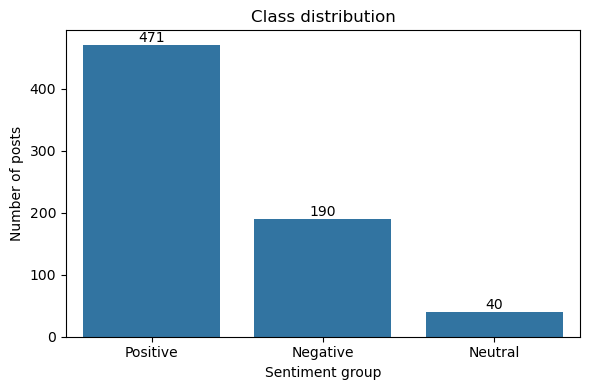

In [15]:
order = ["Positive", "Negative", "Neutral"]

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Sentiment_Group", order=order)
ax.bar_label(ax.containers[0])
plt.title("Class distribution")
plt.xlabel("Sentiment group")
plt.ylabel("Number of posts")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()




Positive makes up about 67% of the data. A model that always predicts Positive would score about 67% accuracy without learning anything, so **macro F1 is the fairer measure**.

### Post length by class


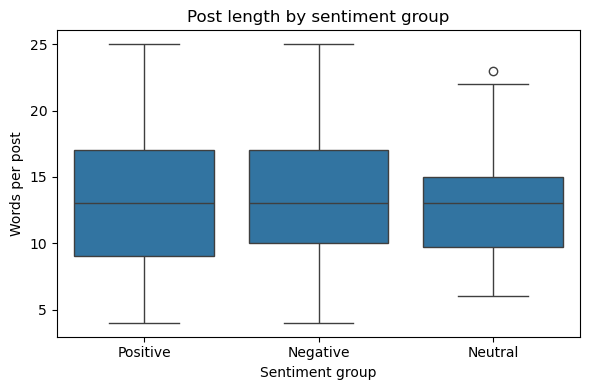

                 count       mean       std  min    25%   50%   75%   max
Sentiment_Group                                                          
Negative         190.0  13.336842  4.785584  4.0  10.00  13.0  17.0  25.0
Neutral           40.0  12.750000  4.055702  6.0   9.75  13.0  15.0  23.0
Positive         471.0  12.940552  4.915961  4.0   9.00  13.0  17.0  25.0


In [16]:
df["word_count"] = df["Text"].str.split().str.len()

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Sentiment_Group", y="word_count", order=order)
plt.title("Post length by sentiment group")
plt.xlabel("Sentiment group")
plt.ylabel("Words per post")
plt.tight_layout()
plt.savefig("post_length_by_class.png", dpi=150)
plt.show()

print(df.groupby("Sentiment_Group")["word_count"].describe())




**Finding.** The median post length is about **13 words in all three classes**. Neutral has a narrower spread (middle half roughly 10 to 15 words, against roughly 9 to 17 for the others) and one outlier near 23 words. The narrower spread is probably a small-sample effect (40 posts). **Post length is unlikely to be driving the predictions.** The `word_count` column is for this chart only and is not used as a model input.

---

## 10. Stratified train/test split


In [17]:
X = df["Text"]
y = df["Sentiment_Group"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())


(560,) (141,)
Sentiment_Group
Positive    376
Negative    152
Neutral      32
Name: count, dtype: int64
Sentiment_Group
Positive    95
Negative    38
Neutral      8
Name: count, dtype: int64


**Findings**

| Set | Posts | Positive | Negative | Neutral |
|---|---|---|---|---|
| Train | 560 | 376 (67.1%) | 152 (27.1%) | 32 (5.7%) |
| Test | 141 | 95 (67.4%) | 38 (27.0%) | 8 (5.7%) |

- `stratify=y` keeps the same class proportions in both sets. Without it, a split this small could leave almost no Neutral posts in the test set.
- `random_state=42` makes the split repeatable.
- **Only 8 Neutral posts are in the test set.** One post changes Neutral recall by 12.5 percentage points, so Neutral scores are noisy.
- The split is done **before** any fitting so that nothing from the test set influences the vocabulary or the weights.

---

## 11. Text preprocessing

**Decisions**

| Step | Choice | Reason |
|---|---|---|
| Emojis | Converted to words | Emojis carry sentiment; converting keeps that signal |
| Hashtags | `#` removed, words kept and split on capitals | `#TeenProblems` becomes "teen problems" |
| URLs | Removed | Carry no sentiment |
| Case | Lowercased | "Joy" and "joy" should match |
| Tokenization | NLTK `RegexpTokenizer`, apostrophes kept inside words | Needs no extra downloads |
| Stopwords | NLTK English list **minus negations** ("no", "nor", "not", all "n't" forms) | Removing "not" would turn "not good" into "good" |
| Normalization | Lemmatization (noun pass, then verb pass) | Gives real words, unlike stemming |


In [18]:
nltk.download("stopwords")
nltk.download("wordnet")

stop_words = set(stopwords.words("english"))
keep = {"no", "nor", "not"} | {w for w in stop_words if "n't" in w}
stop_words = stop_words - keep

tokenizer = RegexpTokenizer(r"[a-z]+(?:'[a-z]+)?")
lemmatizer = WordNetLemmatizer()


def split_camel(word):
    return re.sub(r"(?<=[a-z])(?=[A-Z])", " ", word)


def clean_text(text):
    text = emoji.demojize(text, delimiters=(" ", " ")).replace("_", " ")
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"#(\w+)", lambda m: " " + split_camel(m.group(1)) + " ", text)
    text = text.lower()
    tokens = tokenizer.tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t), pos="v") for t in tokens]
    return " ".join(tokens)


X_train_clean = X_train.apply(clean_text)
X_test_clean = X_test.apply(clean_text)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...


**Examples (before and after)**

| Before | After |
|---|---|
| Resentment building up over past betrayals. | resentment build past betrayal |
| Sinking in despair, each day darker than the last. | sink despair day darker last |
| Elation over discovering a rare book in a quaint bookstore. | elation discover rare book quaint bookstore |
| Embarked on a road trip to revisit cherished places from the past. Nostalgia, the ultimate travel companion. #RoadTrip #NostalgiaTour | embark road trip revisit cherish place past nostalgia ultimate travel companion road trip nostalgia tour |

**Findings**

- Lemmatization works as intended ("building" to "build", "betrayals" to "betrayal", "cherished" to "cherish").
- Small imperfections: adjectives are not lemmatized ("darker" stays "darker"), and a possessive such as "shakira's" is kept.
- **The label word often survives in the post** (resentment, despair, elation, nostalgia). A model can score well partly by spotting that word. This is a limitation of the dataset.
- The cleaning is a fixed set of rules (nothing is learned from data), so it is applied to train and test separately without leakage.

---

## 12. TF-IDF vectorization

**What TF-IDF does.** Each post becomes a vector with one number per vocabulary term. TF-IDF = term frequency x inverse document frequency: a term scores high when it appears often in a post but in few posts overall, and filler words that appear everywhere score near zero. It ignores word order, which word pairs (bigrams) partly address.


In [19]:
print("Empty train posts:", (X_train_clean.str.strip() == "").sum())
print("Empty test posts: ", (X_test_clean.str.strip() == "").sum())

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    token_pattern=r"\S+",
)

X_train_tfidf = tfidf.fit_transform(X_train_clean)   # learn from TRAIN only
X_test_tfidf = tfidf.transform(X_test_clean)         # apply to TEST

print(X_train_tfidf.shape, X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))
density = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print("Share of non-zero cells:", round(density, 4))


Empty train posts: 0
Empty test posts:  0
(560, 1059) (141, 1059)
Vocabulary size: 1059
Share of non-zero cells: 0.0069


| Setting | Value | Reason |
|---|---|---|
| `ngram_range` | (1, 2) | Single words plus word pairs, to capture phrases such as "not good" |
| `min_df` | 2 | Ignore terms appearing in only one post; they cannot generalize |
| `token_pattern` | `\S+` | Text is already cleaned and space-separated; keeps "don't" whole |

**Findings**

- No post was empty after cleaning (0 in train, 0 in test).
- Shapes: train **(560, 1059)**, test **(141, 1059)**. Both have the same 1,059 columns.
- The matrix is very sparse: **0.69% non-zero cells**, roughly 7 active features per post, which is normal for short text.
- Example: the first training post has four active terms (resentment 0.517, past 0.503, build 0.490, betrayal 0.490).
- After vectorizing, **1 training row and 1 test row have no features at all** (every word was filtered by `min_df`). That is negligible, so `min_df=2` was kept.
- **Leakage rule:** the vectorizer is fitted on the training posts only. Test posts are transformed with the vocabulary and IDF weights learned from training; words they contain that training never saw are ignored.

---

## 13. Model training and evaluation

Three models were compared: a majority-class baseline (the score any real model must beat), Logistic Regression with balanced class weights, and Complement Naive Bayes (designed for imbalanced text).


In [20]:
labels = ["Positive", "Negative", "Neutral"]

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ),
    "Complement Naive Bayes": ComplementNB(),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    predictions[name] = pred
    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, labels=labels, zero_division=0))
    print("Macro F1:", round(f1_score(y_test, pred, average="macro",
                                      labels=labels, zero_division=0), 3))


Majority baseline
              precision    recall  f1-score   support

    Positive       0.67      1.00      0.81        95
    Negative       0.00      0.00      0.00        38
     Neutral       0.00      0.00      0.00         8

    accuracy                           0.67       141
   macro avg       0.22      0.33      0.27       141
weighted avg       0.45      0.67      0.54       141

Macro F1: 0.268
Logistic Regression
              precision    recall  f1-score   support

    Positive       0.89      0.93      0.91        95
    Negative       0.89      0.84      0.86        38
     Neutral       0.17      0.12      0.14         8

    accuracy                           0.86       141
   macro avg       0.65      0.63      0.64       141
weighted avg       0.85      0.86      0.85       141

Macro F1: 0.638
Complement Naive Bayes
              precision    recall  f1-score   support

    Positive       0.92      0.87      0.90        95
    Negative       0.85      0.89   

### Test-set results

| Model | Accuracy | Macro F1 |
|---|---|---|
| Majority baseline | 0.67 | 0.268 |
| Logistic Regression | 0.86 | 0.638 |
| Complement Naive Bayes | 0.84 | 0.660 |

### Per-class results (precision / recall / F1)

| Class (test posts) | Baseline | Logistic Regression | Complement NB |
|---|---|---|---|
| Positive (95) | 0.67 / 1.00 / 0.81 | 0.89 / 0.93 / 0.91 | 0.92 / 0.87 / 0.90 |
| Negative (38) | 0.00 / 0.00 / 0.00 | 0.89 / 0.84 / 0.86 | 0.85 / 0.89 / 0.87 |
| Neutral (8) | 0.00 / 0.00 / 0.00 | 0.17 / 0.12 / 0.14 | 0.18 / 0.25 / 0.21 |

**Findings**

- Both models clearly beat the baseline: accuracy rises from 67% to 84 to 86%, and macro F1 from 0.27 to about 0.65.
- **Positive and Negative are learned well** (F1 between 0.86 and 0.91).
- **Neutral is barely learned** (F1 0.14 to 0.21). Logistic Regression found 1 of 8 Neutral test posts; Naive Bayes found 2 of 8.
- **The two models are effectively tied.** Naive Bayes has the higher macro F1 (0.66 against 0.64) while Logistic Regression has the higher accuracy (0.86 against 0.84). The macro F1 gap is about one extra Neutral post, so neither model is declared the winner.

### Confusion matrix (Complement Naive Bayes)


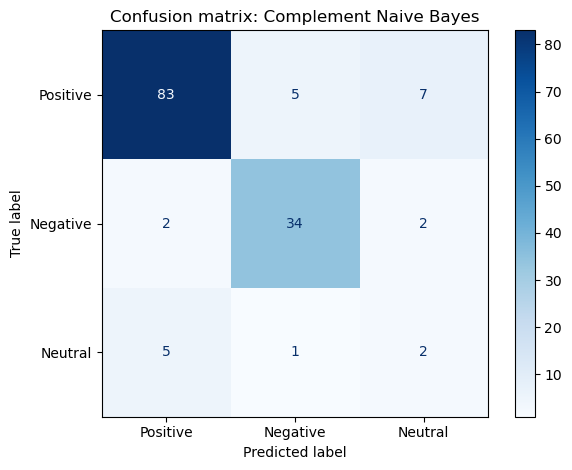

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions["Complement Naive Bayes"], labels=labels, cmap="Blues"
)
plt.title("Confusion matrix: Complement Naive Bayes")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()




| True class | Predicted Positive | Predicted Negative | Predicted Neutral |
|---|---|---|---|
| Positive (95) | 83 | 5 | 7 |
| Negative (38) | 2 | 34 | 2 |
| Neutral (8) | 5 | 1 | 2 |

- Most Positive and Negative posts are on the diagonal (83 of 95 and 34 of 38).
- **5 of the 8 Neutral posts were predicted Positive**, and only 2 were found.
- The model also **over-predicts Neutral**: it said Neutral 11 times but was right only twice, so 9 real Positive or Negative posts were pushed into Neutral. This is the cause of the low Neutral precision.

---

## 14. Error analysis


In [22]:
pd.set_option("display.max_colwidth", None)

results = pd.DataFrame({
    "Text": X_test,
    "True": y_test,
    "NaiveBayes": predictions["Complement Naive Bayes"],
    "LogReg": predictions["Logistic Regression"],
})

results[results["True"] == "Neutral"]
results[(results["NaiveBayes"] == "Neutral") & (results["True"] != "Neutral")]


,Text,True,NaiveBayes,LogReg
46,Attending a virtual reality meetup.,Positive,Neutral,Neutral
697,Facing rejection from a dream college. Disheartened but determined to explore other paths.,Negative,Neutral,Neutral
722,Winning a friendly sports competition against rival schools. Victory celebrations in full swing!,Positive,Neutral,Positive
651,Spent hours perfecting a chemistry experiment. Mixing potions like a wizard!,Positive,Neutral,Negative
663,Trying to set a new trend by juggling textbooks between classes. Academic juggling: A unique skill!,Positive,Neutral,Neutral
29,New painting in progress! 🎨,Positive,Neutral,Positive
682,Trying out a new smoothie recipe for a healthy start to the week. Smoothie enthusiast: Level up!,Positive,Neutral,Neutral
583,Lost my headphones again. How do they vanish into thin air? #HeadphoneMystery #TeenLife,Negative,Neutral,Neutral
644,"Joined the school debate team. Words are my weapons, and I'm ready for battle!",Positive,Neutral,Positive


### The 8 true Neutral test posts

| Post | Naive Bayes | Logistic Regression |
|---|---|---|
| Organizing a community cleanup event for a cleaner neighborhood. Promoting environmental awareness. | Positive | Positive |
| Technology is changing the way we live. | Positive | Positive |
| Collaborating on a group project to promote teamwork and shared responsibilities. Group effort in action. | **Neutral** | Positive |
| Volunteering at a local charity event to give back to the community. Contributing to social causes. | Positive | Positive |
| Ambivalence in the air, caught between the crossroads of conflicting emotions and decisions. | **Neutral** | **Neutral** |
| Exploring a new hobby of photography during free time. Capturing moments through a lens. | Positive | Positive |
| Missing summer vibes and beach days. | Negative | Positive |
| Drifting through the day with a nonchalant demeanor, embracing the art of indifference. | Positive | Positive |

### Real Positive or Negative posts that Naive Bayes called Neutral

"Attending a virtual reality meetup." / "New painting in progress!" / "Trying out a new smoothie recipe for a healthy start to the week." / "Joined the school debate team." / "Facing rejection from a dream college. Disheartened but determined to explore other paths." / "Lost my headphones again. How do they vanish into thin air?" and three more.

**Findings**

- Neutral test posts are of **two kinds**: plain everyday posts (cleanup, volunteering, group project, photography, technology) and poetic posts about ambivalence or indifference.
- The only clear Neutral success is the post containing the label word "Ambivalence".
- Several "Neutral" posts read as mildly positive to a human reader (for example volunteering and giving back), so the **labels themselves are debatable**.
- The posts wrongly called Neutral are **plain, low-key, everyday posts**, the same style as the plain Neutral posts. This suggests the model partly learned "plain everyday post means Neutral", a **writing-style signal rather than a sentiment signal**. This is based on about 17 posts and is suggestive, not proven.
- Some errors are reasonable. "Disheartened but determined" is mixed, and "Lost my headphones" is mild.

---

## 15. Cross-validation

A single 141-post test set (with 8 Neutral posts) is a noisy basis for comparison, so each setup was also evaluated with stratified 5-fold cross-validation on the training set. The vectorizer sits inside a pipeline so it is re-fitted on each fold's training portion only, which prevents leakage.


In [23]:
def make_tfidf(ngrams):
    return TfidfVectorizer(ngram_range=ngrams, min_df=2, token_pattern=r"\S+")

candidates = {
    "LogReg, words + pairs": make_pipeline(
        make_tfidf((1, 2)),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    "LogReg, words only": make_pipeline(
        make_tfidf((1, 1)),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    "NaiveBayes, words + pairs": make_pipeline(make_tfidf((1, 2)), ComplementNB()),
    "NaiveBayes, words only": make_pipeline(make_tfidf((1, 1)), ComplementNB()),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in candidates.items():
    scores = cross_validate(pipe, X_train_clean, y_train, cv=cv,
                            scoring=["f1_macro", "accuracy"])
    print(f"{name:28s} macro F1 {scores['test_f1_macro'].mean():.3f} "
          f"(+/- {scores['test_f1_macro'].std():.3f})   "
          f"accuracy {scores['test_accuracy'].mean():.3f}")


LogReg, words + pairs        macro F1 0.698 (+/- 0.052)   accuracy 0.866
LogReg, words only           macro F1 0.688 (+/- 0.039)   accuracy 0.864
NaiveBayes, words + pairs    macro F1 0.703 (+/- 0.032)   accuracy 0.846
NaiveBayes, words only       macro F1 0.671 (+/- 0.046)   accuracy 0.836


| Setup | Macro F1 (mean ± std) | Accuracy |
|---|---|---|
| Logistic Regression, words + pairs | 0.698 ± 0.052 | 0.866 |
| Logistic Regression, words only | 0.688 ± 0.039 | 0.864 |
| Naive Bayes, words + pairs | 0.703 ± 0.032 | 0.846 |
| Naive Bayes, words only | 0.671 ± 0.046 | 0.836 |

**Findings**

- All four setups are **within noise of each other**: the differences (0.67 to 0.70) are smaller than the fold-to-fold spread (0.03 to 0.05).
- **Word pairs do not clearly help.** The simpler words-only version is a fair choice.
- Cross-validation macro F1 (about 0.70) sits slightly above the test-set macro F1 (0.64 to 0.66). That is consistent with the small Neutral test class, and near-duplicate posts landing in different folds may also inflate cross-validation a little. Both sets of numbers are reported.

---

## 16. Conclusions

- Both Logistic Regression and Complement Naive Bayes reach **84 to 86% accuracy and a macro F1 of about 0.65 to 0.70**, far above the majority baseline (67% accuracy, 0.27 macro F1). Neither model is clearly better.
- **Positive and Negative are learned reliably** (F1 about 0.86 to 0.91).
- **Neutral is weak** (F1 0.14 to 0.21). The class is small (40 posts) and heterogeneous: it mixes plain everyday posts with poetic posts about ambivalence and indifference, so it has no single vocabulary to learn.
- Error analysis suggests the models partly use **writing style** to predict Neutral.
- The largest source of uncertainty is not the model but the **labels**: grouping 191 emotions into three classes involved judgment calls, and those decisions are recorded in sections 5 and 6.

---

## 17. Limitations

1. **Manual label grouping.** 191 emotion labels were mapped to three classes by reading posts. Reasonable people could group some labels differently (for example Nostalgia, Boredom, Emotion).
2. **Tiny Neutral class.** 40 posts in total and only 8 in the test set; one post moves Neutral recall by 12.5 percentage points. Neutral scores should not be over-interpreted.
3. **Label words appear in the posts.** Many posts contain their own label word (nostalgia, confusion, numbness), so a model can score well by spotting that word without understanding sentiment.
4. **Near-duplicate posts remain.** Only exact duplicates were removed, so train and test may share near-identical posts, which can make scores slightly optimistic.
5. **Batch-generated text.** The data shows signs of being generated in blocks with different styles (ornate poetic posts and plain teen-style posts), which a model can pick up as a style signal.
6. **Row removals.** Five rows were removed by judgment (documented in section 6).
7. **TF-IDF ignores word order and meaning.** Negation is only partly handled through bigrams and kept stopwords. Embedding-based or transformer models would handle context better.

---

## 18. Reproducibility

- Python libraries: pandas, numpy, matplotlib, seaborn, scikit-learn, nltk, emoji.
- NLTK resources: `stopwords`, `wordnet`.
- Fixed seeds: `random_state=42` for the train/test split, cross-validation and Logistic Regression.
- Run the notebook top to bottom. Row-dropping cells (section 6) should run once and before the mapping cell.
- Suggested repository layout:

```
level3/
  nlp_sentiment_classification.ipynb
  NLP_sentiment_classification.md
  images/
    class_distribution.png
    post_length_by_class.png
    confusion_matrix.png
```
